In [ ]:
!pip -q install -U datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 32.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 18.7 MB/s eta 0:00:00


In [ ]:
from datasets import load_dataset

dataset = load_dataset(
    "geraldmc/plantvillage-full",
    split="train"
)

print(dataset)
print("Columns:", dataset.column_names)
print("First example:", dataset[0].keys())

README.md:   0%|          | 0.00/5.86k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  402MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  453MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/54304 [00:00<?, ? examples/s]

Dataset({
    features: ['image', 'class_label', 'class_idx', 'host', 'disease', 'split', 'leaf_id', 'leaf_grouped'],
    num_rows: 54304
})
Columns: ['image', 'class_label', 'class_idx', 'host', 'disease', 'split', 'leaf_id', 'leaf_grouped']
First example: dict_keys(['image', 'class_label', 'class_idx', 'host', 'disease', 'split', 'leaf_id', 'leaf_grouped'])


In [ ]:
# Check all unique plant-disease classes
classes = sorted(set(dataset["class_label"]))

print("Total classes:", len(classes))
print("\nTomato classes:")

for name in classes:
    if "tomato" in name.lower():
        print(name)

Total classes: 38

Tomato classes:
Tomato___Bacterial_spot
Tomato___Early_blight
Tomato___Late_blight
Tomato___Leaf_Mold
Tomato___Septoria_leaf_spot
Tomato___Spider_mites Two-spotted_spider_mite
Tomato___Target_Spot
Tomato___Tomato_Yellow_Leaf_Curl_Virus
Tomato___Tomato_mosaic_virus
Tomato___healthy


In [ ]:
from collections import Counter

# The three classes required for our experiment
target_classes = [
    "Tomato___healthy",
    "Tomato___Early_blight",
    "Tomato___Late_blight"
]

# Check whether the names match the dataset exactly
available_classes = set(dataset["class_label"])

for name in target_classes:
    print(name, "->", name in available_classes)

Tomato___healthy -> True
Tomato___Early_blight -> True
Tomato___Late_blight -> True


In [ ]:
tomato_data = dataset.filter(
    lambda row: row["class_label"] in target_classes
)

print("Total selected images:", len(tomato_data))
print("\nImages per class:")

counts = Counter(tomato_data["class_label"])

for name, count in counts.items():
    print(f"{name}: {count}")

Filter:   0%|          | 0/54304 [00:00<?, ? examples/s]

Total selected images: 4500

Images per class:
Tomato___Early_blight: 1000
Tomato___Late_blight: 1909
Tomato___healthy: 1591


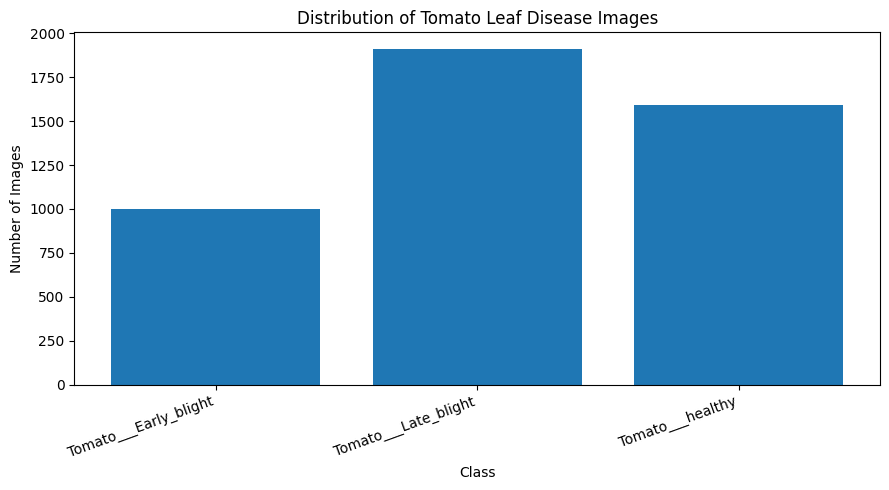

In [ ]:
import matplotlib.pyplot as plt
from collections import Counter

counts = Counter(tomato_data["class_label"])

labels = list(counts.keys())
values = list(counts.values())

plt.figure(figsize=(9, 5))
plt.bar(labels, values)
plt.title("Distribution of Tomato Leaf Disease Images")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig("task1_class_distribution.png", dpi=300)
plt.show()

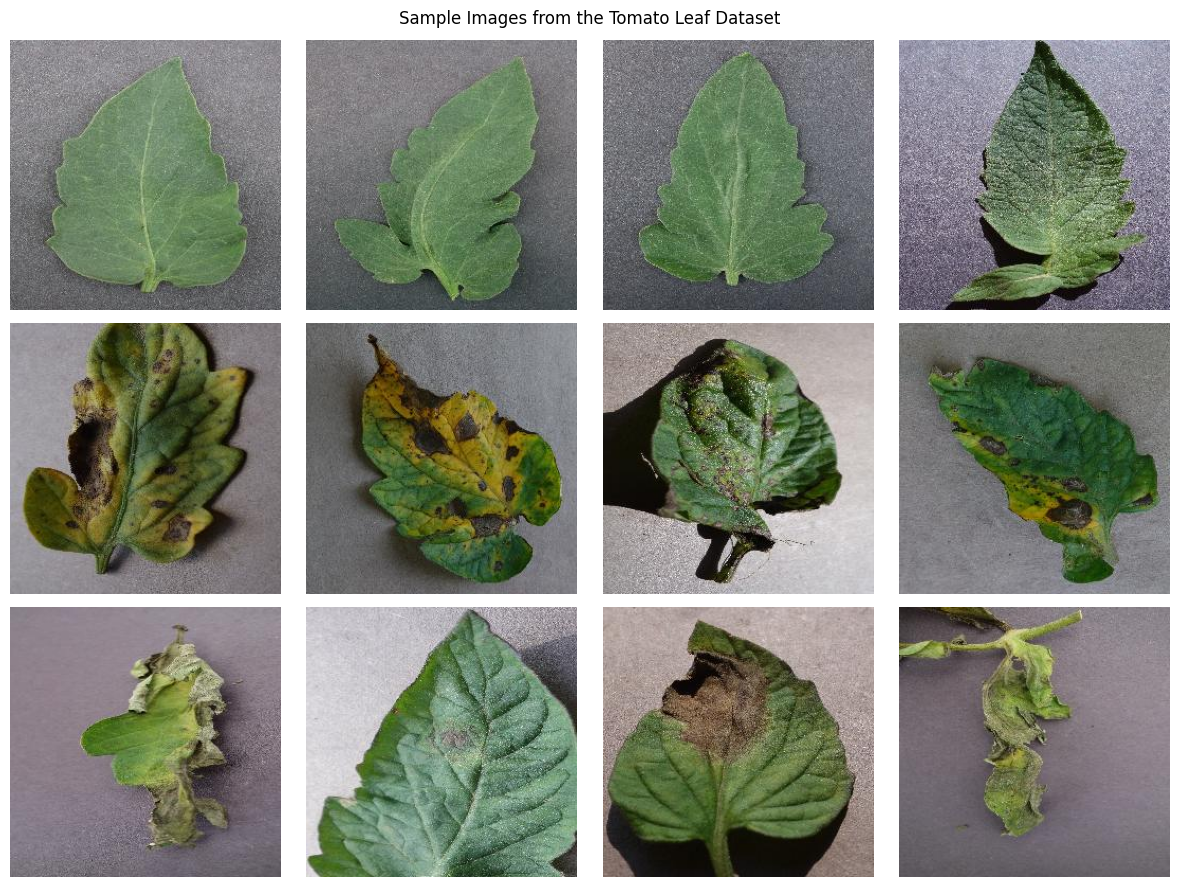

In [ ]:
import random
import matplotlib.pyplot as plt

random.seed(42)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for row, class_name in enumerate(target_classes):
    # Find image indices belonging to this class
    indices = [
        i for i, label in enumerate(tomato_data["class_label"])
        if label == class_name
    ]

    # Pick four images from this class
    chosen = random.sample(indices, 4)

    for col, idx in enumerate(chosen):
        image = tomato_data[idx]["image"]
        axes[row, col].imshow(image)
        axes[row, col].axis("off")

        if col == 0:
            axes[row, col].set_ylabel(
                class_name.replace("Tomato___", ""),
                fontsize=9
            )

plt.suptitle("Sample Images from the Tomato Leaf Dataset")
plt.tight_layout()
plt.savefig("task1_sample_images.png", dpi=300)
plt.show()

In [ ]:
import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split

X_list = []
y_list = []

for item in tomato_data:
    img = item["image"].convert("L")
    img = img.resize((64, 64))

    # Convert pixels to values between 0 and 1
    arr = np.array(img, dtype=np.float32) / 255.0

    # Flatten 64 x 64 into 4096 features
    X_list.append(arr.flatten())
    y_list.append(item["class_label"])

X = np.array(X_list, dtype=np.float32)
y = np.array(y_list)

print("Feature matrix shape:", X.shape)
print("Label vector shape:", y.shape)
print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())

Feature matrix shape: (4500, 4096)
Label vector shape: (4500,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set:", X_test.shape, y_test.shape)

Training set: (3150, 4096) (3150,)
Validation set: (675, 4096) (675,)
Test set: (675, 4096) (675,)


PCA fitting time: 5.60 seconds
Variance explained by first 10 components: 61.69%
Variance explained by first 50 components: 78.20%
Variance explained by first 100 components: 84.34%


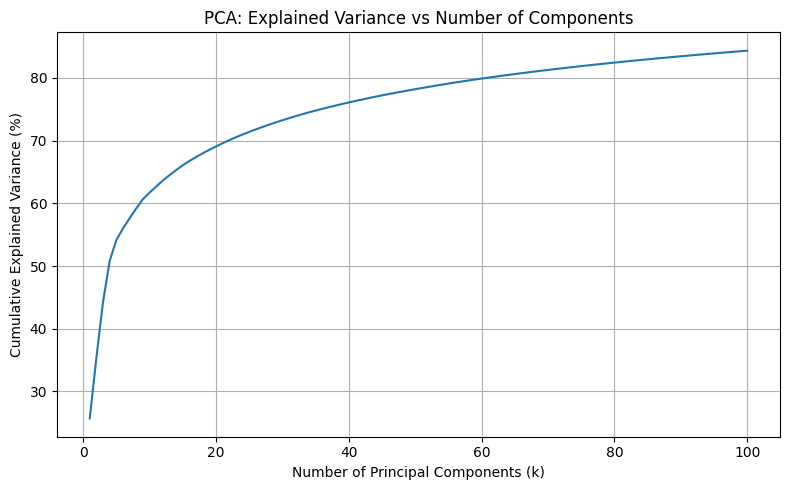

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
import time

# Fit PCA using training data only
start = time.time()

pca = PCA(
    n_components=100,
    svd_solver="randomized",
    random_state=42
)

pca.fit(X_train)

pca_time = time.time() - start

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

print(f"PCA fitting time: {pca_time:.2f} seconds")
print("Variance explained by first 10 components:",
      f"{cumulative_variance[9] * 100:.2f}%")
print("Variance explained by first 50 components:",
      f"{cumulative_variance[49] * 100:.2f}%")
print("Variance explained by first 100 components:",
      f"{cumulative_variance[99] * 100:.2f}%")

# Plot cumulative explained variance
plt.figure(figsize=(8, 5))
plt.plot(range(1, 101), cumulative_variance * 100)
plt.xlabel("Number of Principal Components (k)")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA: Explained Variance vs Number of Components")
plt.grid(True)
plt.tight_layout()
plt.savefig("task2_explained_variance.png", dpi=300)
plt.show()

k =   5 | Reconstruction MSE = 0.013000
k =  10 | Reconstruction MSE = 0.010902
k =  20 | Reconstruction MSE = 0.008890
k =  50 | Reconstruction MSE = 0.006463
k = 100 | Reconstruction MSE = 0.004901


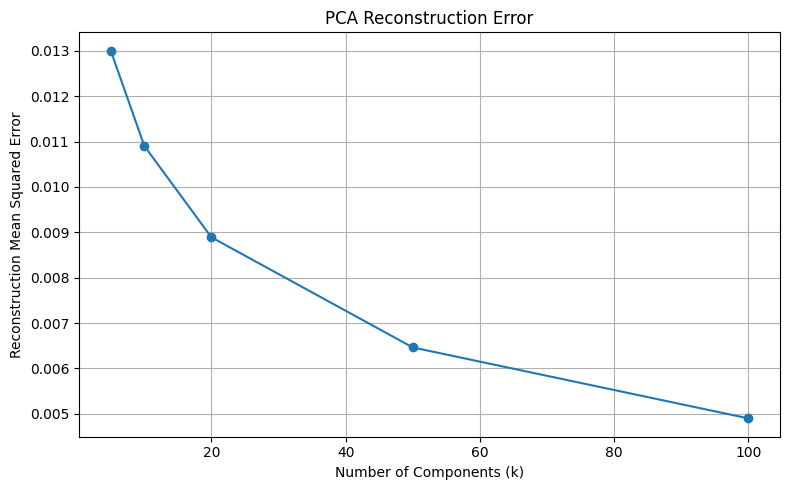

In [ ]:
component_values = [5, 10, 20, 50, 100]
reconstruction_errors = []

for k in component_values:
    # Use the first k components from the fitted PCA
    reduced = pca.transform(X_test)[:, :k]

    reconstructed = (
        reduced @ pca.components_[:k]
        + pca.mean_
    )

    mse = mean_squared_error(X_test, reconstructed)
    reconstruction_errors.append(mse)

    print(f"k = {k:3d} | Reconstruction MSE = {mse:.6f}")

plt.figure(figsize=(8, 5))
plt.plot(component_values, reconstruction_errors, marker="o")
plt.xlabel("Number of Components (k)")
plt.ylabel("Reconstruction Mean Squared Error")
plt.title("PCA Reconstruction Error")
plt.grid(True)
plt.tight_layout()
plt.savefig("task2_reconstruction_error.png", dpi=300)
plt.show()

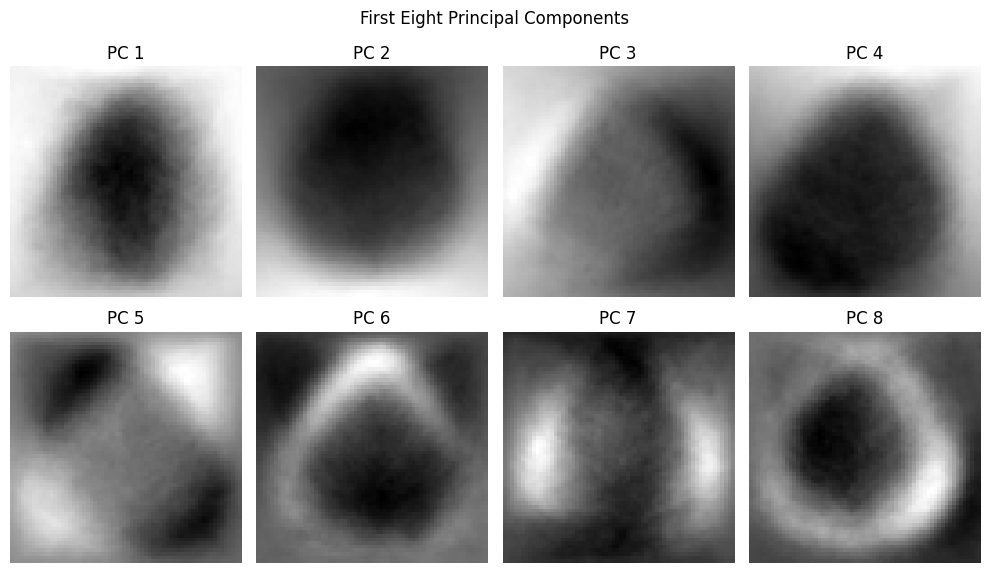

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(10, 6))

for i, ax in enumerate(axes.flat):
    component_image = pca.components_[i].reshape(64, 64)

    ax.imshow(component_image, cmap="gray")
    ax.set_title(f"PC {i + 1}")
    ax.axis("off")

plt.suptitle("First Eight Principal Components")
plt.tight_layout()
plt.savefig("task2_principal_components.png", dpi=300)
plt.show()

TASK 3

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

counts = Counter(tomato_data["class_label"])
total = sum(counts.values())

classes = list(counts.keys())
probabilities = np.array([counts[c] / total for c in classes])

# Shannon entropy: H(Y) = -sum(p * log2(p))
entropy = -np.sum(probabilities * np.log2(probabilities))

print("Class probabilities:")
for name, p in zip(classes, probabilities):
    print(f"{name}: {p:.4f}")

print(f"\nClass entropy: {entropy:.4f} bits")
print(f"Maximum possible entropy: {np.log2(len(classes)):.4f} bits")

Class probabilities:
Tomato___Early_blight: 0.2222
Tomato___Late_blight: 0.4242
Tomato___healthy: 0.3536

Class entropy: 1.5373 bits
Maximum possible entropy: 1.5850 bits


In [ ]:
import numpy as np

# Illustrative true and predicted probability distributions
p = np.array([0.7, 0.2, 0.1])  # True distribution
q = np.array([0.5, 0.3, 0.2])  # Predicted distribution

# Entropy of the true distribution
H_p = -np.sum(p * np.log2(p))

# Cross-entropy: H(P, Q)
cross_entropy = -np.sum(p * np.log2(q))

# KL divergence in both directions
kl_pq = np.sum(p * np.log2(p / q))
kl_qp = np.sum(q * np.log2(q / p))

print(f"Entropy H(P): {H_p:.4f} bits")
print(f"Cross-entropy H(P,Q): {cross_entropy:.4f} bits")
print(f"KL divergence D(P||Q): {kl_pq:.4f} bits")
print(f"KL divergence D(Q||P): {kl_qp:.4f} bits")

print("\nCheck: Cross-entropy = Entropy + KL divergence")
print(f"{cross_entropy:.4f} = {H_p:.4f} + {kl_pq:.4f}")

Entropy H(P): 1.1568 bits
Cross-entropy H(P,Q): 1.2796 bits
KL divergence D(P||Q): 0.1228 bits
KL divergence D(Q||P): 0.1328 bits

Check: Cross-entropy = Entropy + KL divergence
1.2796 = 1.1568 + 0.1228


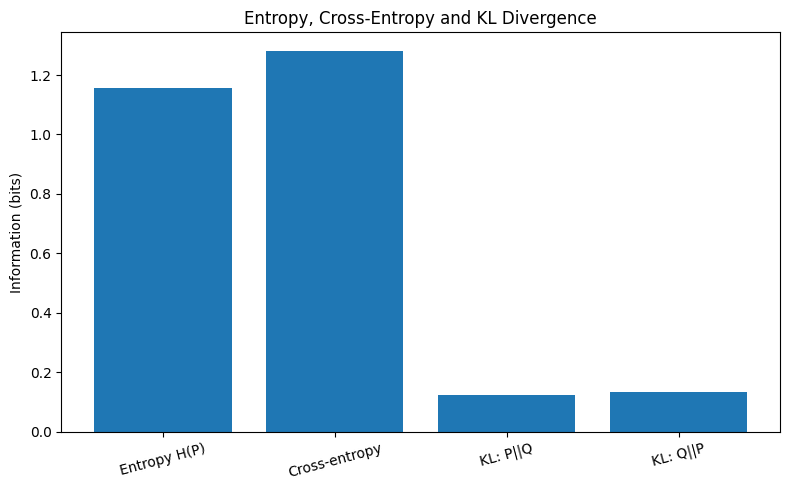

In [ ]:
names = [
    "Entropy H(P)",
    "Cross-entropy",
    "KL: P||Q",
    "KL: Q||P"
]

values = [H_p, cross_entropy, kl_pq, kl_qp]

plt.figure(figsize=(8, 5))
plt.bar(names, values)
plt.ylabel("Information (bits)")
plt.title("Entropy, Cross-Entropy and KL Divergence")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("task3_information_theory.png", dpi=300)
plt.show()

TASK 4

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

z = np.array([1000.0, 999.0, 995.0])

# Naive softmax
with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
    exp_z = np.exp(z)
    naive_softmax = exp_z / np.sum(exp_z)

# Numerically stable softmax
shifted_z = z - np.max(z)
exp_shifted = np.exp(shifted_z)
stable_softmax = exp_shifted / np.sum(exp_shifted)

print("Logits:", z)
print("Naive softmax:", naive_softmax)
print("Stable softmax:", stable_softmax)
print("Stable probabilities sum:", stable_softmax.sum())

Logits: [1000.  999.  995.]
Naive softmax: [nan nan nan]
Stable softmax: [0.72747516 0.26762315 0.00490169]
Stable probabilities sum: 1.0000000000000002


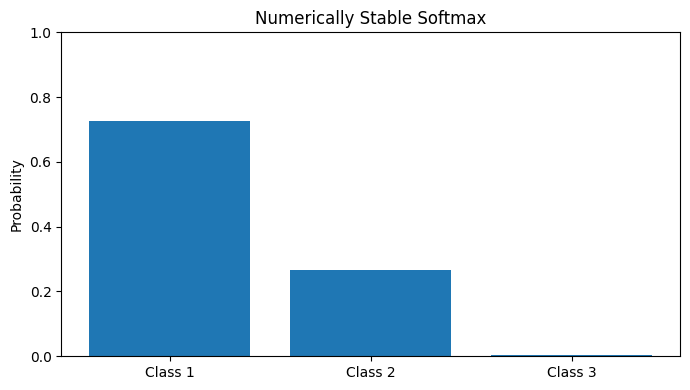

In [ ]:
plt.figure(figsize=(7, 4))
plt.bar(["Class 1", "Class 2", "Class 3"], stable_softmax)
plt.ylabel("Probability")
plt.title("Numerically Stable Softmax")
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig("task4_stable_softmax.png", dpi=300)
plt.show()

In [ ]:
# Use a subset to keep the computation quick
X_condition = X_train[:1000, :256].astype(np.float64)

# Center each feature
X_centered = X_condition - X_condition.mean(axis=0)

# Covariance matrix of the selected features
cov_matrix = np.cov(X_centered, rowvar=False)

# Eigenvalues of the symmetric covariance matrix
eigenvalues = np.linalg.eigvalsh(cov_matrix)

largest = np.max(eigenvalues)
smallest = np.min(eigenvalues)

# Avoid division by zero if the matrix is singular
tolerance = np.finfo(float).eps * largest * len(eigenvalues)
positive_eigenvalues = eigenvalues[eigenvalues > tolerance]

if len(positive_eigenvalues) < len(eigenvalues):
    print("Some covariance directions are numerically zero.")
    print("The covariance matrix is singular or nearly singular.")
else:
    condition_number = largest / smallest
    print(f"Estimated condition number: {condition_number:.4e}")

print(f"Largest eigenvalue: {largest:.6e}")
print(f"Smallest eigenvalue: {smallest:.6e}")

Estimated condition number: 1.2536e+05
Largest eigenvalue: 4.901950e+00
Smallest eigenvalue: 3.910390e-05


TASK 5

In [ ]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

# Use smaller subsets to reduce runtime
Xtr, _, ytr, _ = train_test_split(
    X_train, y_train,
    train_size=1500,
    random_state=42,
    stratify=y_train
)

Xte, _, yte, _ = train_test_split(
    X_test, y_test,
    train_size=300,
    random_state=42,
    stratify=y_test
)

# PCA compression: retain the first 50 components
Xtr_pca = pca.transform(Xtr)[:, :50]
Xte_pca = pca.transform(Xte)[:, :50]

print("Raw training shape:", Xtr.shape)
print("PCA training shape:", Xtr_pca.shape)
print("Test images:", len(yte))

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=200, random_state=42
    ),
    "k-NN": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(
        n_estimators=80,
        max_depth=20,
        random_state=42,
        n_jobs=-1
    )
}

results = []

for feature_type, X_train_used, X_test_used in [
    ("Raw 4096 features", Xtr, Xte),
    ("PCA 50 components", Xtr_pca, Xte_pca)
]:
    for model_name, model in models.items():
        start = time.time()
        model.fit(X_train_used, ytr)
        train_time = time.time() - start

        start = time.time()
        predictions = model.predict(X_test_used)
        predict_time = time.time() - start

        accuracy = accuracy_score(yte, predictions)
        macro_f1 = f1_score(
            yte, predictions, average="macro"
        )

        results.append({
            "Features": feature_type,
            "Model": model_name,
            "Accuracy": accuracy,
            "Macro F1": macro_f1,
            "Training time (s)": train_time,
            "Prediction time (s)": predict_time
        })

results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON")
display(results_df.round(4))

results_df.to_csv("task5_model_comparison.csv", index=False)

Raw training shape: (1500, 4096)
PCA training shape: (1500, 50)
Test images: 300


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



MODEL COMPARISON


,Features,Model,Accuracy,Macro F1,Training time (s),Prediction time (s)
0,Raw 4096 features,Logistic Regression,0.5733,0.5670,31.3465,0.0096
1,Raw 4096 features,k-NN,0.6033,0.6056,0.0156,0.4167
2,Raw 4096 features,Random Forest,0.8133,0.7902,7.0861,0.0364
3,PCA 50 components,Logistic Regression,0.6233,0.6250,0.0400,0.0006
4,PCA 50 components,k-NN,0.7633,0.7481,0.0024,0.0157
5,PCA 50 components,Random Forest,0.7967,0.7726,0.8804,0.0346


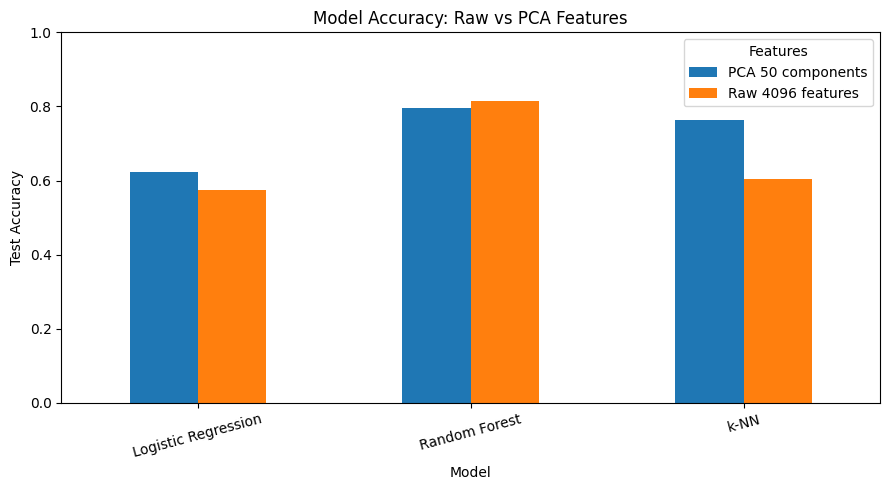

In [ ]:
pivot = results_df.pivot(
    index="Model",
    columns="Features",
    values="Accuracy"
)

pivot.plot(kind="bar", figsize=(9, 5))
plt.title("Model Accuracy: Raw vs PCA Features")
plt.xlabel("Model")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("task5_model_accuracy.png", dpi=300)
plt.show()

TASK 6

In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

# Use a manageable subset of the training and validation sets
X6_train, _, y6_train, _ = train_test_split(
    X_train, y_train,
    train_size=1200,
    random_state=42,
    stratify=y_train
)

X6_val, _, y6_val, _ = train_test_split(
    X_val, y_val,
    train_size=500,
    random_state=42,
    stratify=y_val
)

depths = [1, 2, 3, 5, 10, 20, None]
results6 = []

for depth in depths:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X6_train, y6_train)

    train_acc = accuracy_score(
        y6_train, model.predict(X6_train)
    )
    val_acc = accuracy_score(
        y6_val, model.predict(X6_val)
    )

    results6.append({
        "Maximum depth": str(depth),
        "Training accuracy": train_acc,
        "Validation accuracy": val_acc,
        "Training error": 1 - train_acc,
        "Validation error": 1 - val_acc,
        "Generalization gap": train_acc - val_acc
    })

results6_df = pd.DataFrame(results6)
display(results6_df.round(4))

results6_df.to_csv("task6_capacity_results.csv", index=False)

,Maximum depth,Training accuracy,Validation accuracy,Training error,Validation error,Generalization gap
0,1,0.4842,0.466,0.5158,0.534,0.0182
1,2,0.5592,0.502,0.4408,0.498,0.0572
2,3,0.6717,0.548,0.3283,0.452,0.1237
3,5,0.7842,0.594,0.2158,0.406,0.1902
4,10,0.9867,0.664,0.0133,0.336,0.3227
5,20,1.0000,0.646,0.0000,0.354,0.3540
6,None,1.0000,0.646,0.0000,0.354,0.3540


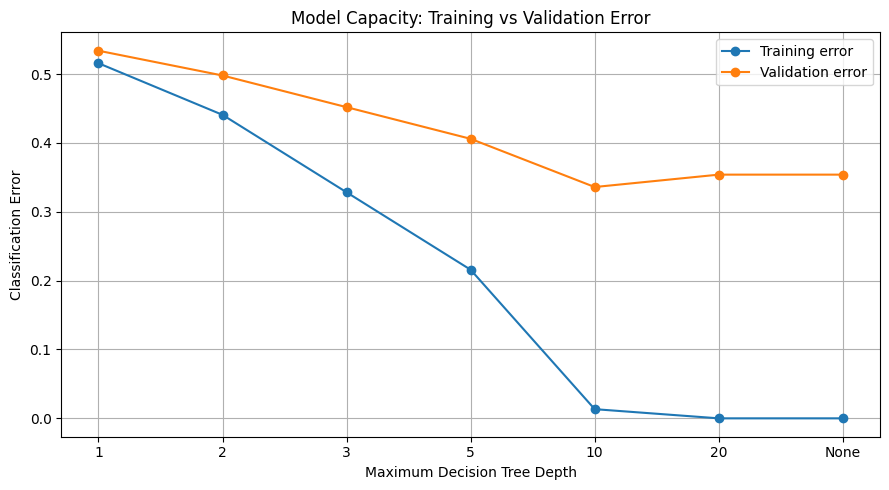

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    results6_df["Maximum depth"],
    results6_df["Training error"],
    marker="o",
    label="Training error"
)

plt.plot(
    results6_df["Maximum depth"],
    results6_df["Validation error"],
    marker="o",
    label="Validation error"
)

plt.xlabel("Maximum Decision Tree Depth")
plt.ylabel("Classification Error")
plt.title("Model Capacity: Training vs Validation Error")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("task6_capacity_error.png", dpi=300)
plt.show()

TASK 7

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Small subsets for faster execution
X7_train, _, y7_train, _ = train_test_split(
    X_train, y_train,
    train_size=800,
    random_state=42,
    stratify=y_train
)

X7_val, _, y7_val, _ = train_test_split(
    X_val, y_val,
    train_size=250,
    random_state=42,
    stratify=y_val
)

classes = np.unique(y7_train)
y_val_encoded = np.searchsorted(classes, y7_val)

# Convert true labels into one-hot vectors
Y_true = np.eye(len(classes))[y_val_encoded]

rng = np.random.default_rng(42)
bootstrap_probabilities = []
bootstrap_accuracies = []

n = len(y7_train)
n_bootstrap = 15

for b in range(n_bootstrap):
    # Sample training rows with replacement
    indices = rng.choice(n, size=n, replace=True)

    model = DecisionTreeClassifier(
        max_depth=10,
        random_state=100 + b
    )

    model.fit(X7_train[indices], y7_train[indices])

    # Align probabilities to the same class order
    raw_probs = model.predict_proba(X7_val)
    probs = np.zeros((len(y7_val), len(classes)))

    for j, cls in enumerate(model.classes_):
        class_position = np.where(classes == cls)[0][0]
        probs[:, class_position] = raw_probs[:, j]

    bootstrap_probabilities.append(probs)
    bootstrap_accuracies.append(
        accuracy_score(y7_val, model.predict(X7_val))
    )

bootstrap_probabilities = np.array(bootstrap_probabilities)

# Average predictions across bootstrap models
mean_probs = bootstrap_probabilities.mean(axis=0)

# Approximate bias and variance using squared probability error
bias_squared = np.mean((mean_probs - Y_true) ** 2)
variance = np.mean(
    np.var(bootstrap_probabilities, axis=0, ddof=0)
)

print("Number of bootstrap models:", n_bootstrap)
print(f"Mean validation accuracy: {np.mean(bootstrap_accuracies):.4f}")
print(f"Accuracy standard deviation: {np.std(bootstrap_accuracies):.4f}")
print(f"Squared-bias proxy: {bias_squared:.6f}")
print(f"Prediction-variance estimate: {variance:.6f}")
print(f"Combined error proxy: {bias_squared + variance:.6f}")

Number of bootstrap models: 15
Mean validation accuracy: 0.5381
Accuracy standard deviation: 0.0315
Squared-bias proxy: 0.146204
Prediction-variance estimate: 0.158340
Combined error proxy: 0.304544


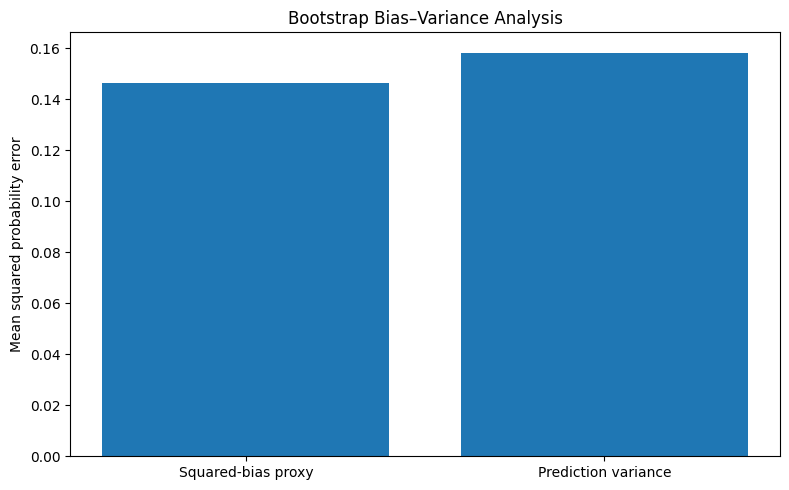

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    ["Squared-bias proxy", "Prediction variance"],
    [bias_squared, variance]
)

plt.ylabel("Mean squared probability error")
plt.title("Bootstrap Bias–Variance Analysis")
plt.tight_layout()
plt.savefig("task7_bias_variance.png", dpi=300)
plt.show()

TASK 8

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Use a manageable subset of the existing training data
X8, _, y8, _ = train_test_split(
    X_train, y_train,
    train_size=1200,
    random_state=42,
    stratify=y_train
)

# Use 300 validation examples
X8_val, _, y8_val, _ = train_test_split(
    X_val, y_val,
    train_size=300,
    random_state=42,
    stratify=y_val
)

# Reduce 4096 pixels to 50 PCA features
X8 = pca.transform(X8)[:, :50]
X8_val = pca.transform(X8_val)[:, :50]

# Standardize using training data only
scaler8 = StandardScaler()
X8 = scaler8.fit_transform(X8)
X8_val = scaler8.transform(X8_val)

encoder8 = LabelEncoder()
y8_encoded = encoder8.fit_transform(y8)
y8_val_encoded = encoder8.transform(y8_val)

num_classes = len(encoder8.classes_)
num_features = X8.shape[1]

Y8 = np.eye(num_classes)[y8_encoded]
Y8_val = np.eye(num_classes)[y8_val_encoded]

print("Training shape:", X8.shape)
print("Validation shape:", X8_val.shape)
print("Number of classes:", num_classes)


# Stable softmax: subtract max logit before exponentiation
def softmax(logits):
    shifted = logits - np.max(logits, axis=1, keepdims=True)
    exp_values = np.exp(shifted)
    return exp_values / np.sum(exp_values, axis=1, keepdims=True)


def cross_entropy(X, Y, W, b):
    probs = softmax(X @ W + b)
    return -np.mean(np.sum(Y * np.log(probs + 1e-12), axis=1))


def train_softmax(X, Y, X_val, Y_val,
                  method, learning_rate, epochs=20):

    rng = np.random.default_rng(42)

    W = np.zeros((X.shape[1], Y.shape[1]))
    b = np.zeros(Y.shape[1])

    losses = []
    start = time.time()

    for epoch in range(epochs):

        if method == "Batch GD":
            batches = [np.arange(len(X))]

        elif method == "SGD":
            batches = [
                np.array([i])
                for i in rng.permutation(len(X))
            ]

        else:  # Mini-batch SGD
            shuffled = rng.permutation(len(X))
            batches = [
                shuffled[i:i + 64]
                for i in range(0, len(X), 64)
            ]

        for indices in batches:
            xb = X[indices]
            yb = Y[indices]

            probs = softmax(xb @ W + b)

            # Gradients derived from cross-entropy loss
            error = probs - yb
            grad_W = xb.T @ error / len(xb)
            grad_b = np.mean(error, axis=0)

            W -= learning_rate * grad_W
            b -= learning_rate * grad_b

        losses.append(cross_entropy(X_val, Y_val, W, b))

    elapsed = time.time() - start
    return W, b, losses, elapsed


# Compare 3 optimisation methods and 3 learning rates
learning_rates = [0.001, 0.01, 0.1]
methods = ["Batch GD", "SGD", "Mini-batch SGD"]

results8 = {}
summary8 = []

for method in methods:
    for lr in learning_rates:

        W, b, losses, elapsed = train_softmax(
            X8, Y8, X8_val, Y8_val,
            method=method,
            learning_rate=lr,
            epochs=20
        )

        results8[(method, lr)] = losses

        final_probs = softmax(X8_val @ W + b)
        predictions = np.argmax(final_probs, axis=1)
        accuracy = np.mean(predictions == y8_val_encoded)

        summary8.append({
            "Method": method,
            "Learning rate": lr,
            "Final validation loss": losses[-1],
            "Validation accuracy": accuracy,
            "Training time (s)": elapsed
        })

summary8 = sorted(
    summary8,
    key=lambda row: row["Final validation loss"]
)

for row in summary8:
    print(row)

print("\nLowest validation loss:")
print(summary8[0])

Training shape: (1200, 50)
Validation shape: (300, 50)
Number of classes: 3
{'Method': 'SGD', 'Learning rate': 0.001, 'Final validation loss': np.float64(0.8247191637709903), 'Validation accuracy': np.float64(0.6266666666666667), 'Training time (s)': 4.679855585098267}
{'Method': 'Mini-batch SGD', 'Learning rate': 0.1, 'Final validation loss': np.float64(0.8266576961433908), 'Validation accuracy': np.float64(0.6166666666666667), 'Training time (s)': 0.1525874137878418}
{'Method': 'SGD', 'Learning rate': 0.01, 'Final validation loss': np.float64(0.8793935441101322), 'Validation accuracy': np.float64(0.5933333333333334), 'Training time (s)': 3.3664841651916504}
{'Method': 'Mini-batch SGD', 'Learning rate': 0.01, 'Final validation loss': np.float64(0.8799099626000574), 'Validation accuracy': np.float64(0.62), 'Training time (s)': 0.1382617950439453}
{'Method': 'Batch GD', 'Learning rate': 0.1, 'Final validation loss': np.float64(0.9313925690674871), 'Validation accuracy': np.float64(0.626

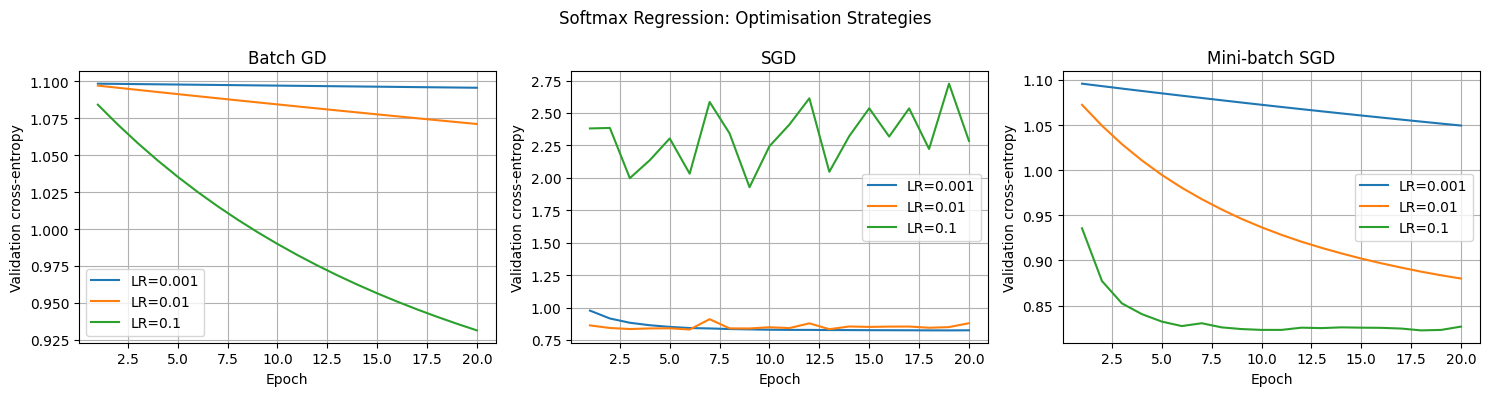

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, method in zip(axes, methods):
    for lr in learning_rates:
        ax.plot(
            range(1, 21),
            results8[(method, lr)],
            label=f"LR={lr}"
        )

    ax.set_title(method)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Validation cross-entropy")
    ax.legend()
    ax.grid(True)

plt.suptitle("Softmax Regression: Optimisation Strategies")
plt.tight_layout()
plt.savefig("task8_optimisation_curves.png", dpi=300)
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay
)

# Transform the existing splits into 50 PCA features
X9_train = pca.transform(X_train)[:, :50]
X9_test = pca.transform(X_test)[:, :50]

# Use a fixed test set for fair comparisons
dataset_sizes = [1000, 2000, len(X9_train)]
dataset_sizes = sorted(set(dataset_sizes))

models9 = {
    "Logistic Regression": LogisticRegression(
        max_iter=300, random_state=42
    ),
    "k-NN": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(
        n_estimators=60,
        max_depth=20,
        random_state=42,
        n_jobs=-1
    )
}

results9 = []
saved_models9 = {}

rng = np.random.default_rng(42)

for size in dataset_sizes:
    # Select a stratified subset so class proportions remain similar
    if size == len(X9_train):
        indices = np.arange(len(X9_train))
    else:
        # Stratified selection based on class labels
        from sklearn.model_selection import train_test_split
        indices, _ = train_test_split(
            np.arange(len(y_train)),
            train_size=size,
            random_state=42,
            stratify=y_train
        )

    Xs = X9_train[indices]
    ys = y_train[indices]

    print(f"\nTraining size: {len(Xs)}")

    for model_name, base_model in models9.items():
        # Create a fresh model for every dataset size
        from sklearn.base import clone
        model = clone(base_model)

        start = time.time()
        model.fit(Xs, ys)
        train_time = time.time() - start

        start = time.time()
        pred = model.predict(X9_test)
        inference_time = time.time() - start

        results9.append({
            "Training images": len(Xs),
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, pred),
            "Macro precision": precision_score(
                y_test, pred, average="macro", zero_division=0
            ),
            "Macro recall": recall_score(
                y_test, pred, average="macro", zero_division=0
            ),
            "Macro F1": f1_score(
                y_test, pred, average="macro", zero_division=0
            ),
            "Training time (s)": train_time,
            "Inference time (s)": inference_time
        })

        saved_models9[(len(Xs), model_name)] = model

results9_df = pd.DataFrame(results9)
display(results9_df.round(4))

results9_df.to_csv("task9_performance_results.csv", index=False)


Training size: 1000

Training size: 2000

Training size: 3150


,Training images,Model,Accuracy,Macro precision,Macro recall,Macro F1,Training time (s),Inference time (s)
0,1000,Logistic Regression,0.6193,0.6213,0.6160,0.6182,0.2539,0.0031
1,1000,k-NN,0.7659,0.7527,0.7626,0.7519,0.0043,0.0616
2,1000,Random Forest,0.7807,0.7724,0.7443,0.7531,1.0712,0.0572
3,2000,Logistic Regression,0.6400,0.6390,0.6352,0.6370,0.1218,0.0026
4,2000,k-NN,0.7704,0.7549,0.7591,0.7536,0.0048,0.0413
5,2000,Random Forest,0.8089,0.7942,0.7805,0.7859,1.7090,0.0435
6,3150,Logistic Regression,0.6430,0.6424,0.6372,0.6396,0.1869,0.0007
7,3150,k-NN,0.8059,0.7913,0.7978,0.7925,0.0037,0.0488
8,3150,Random Forest,0.8089,0.7942,0.7795,0.7852,2.7488,0.0633


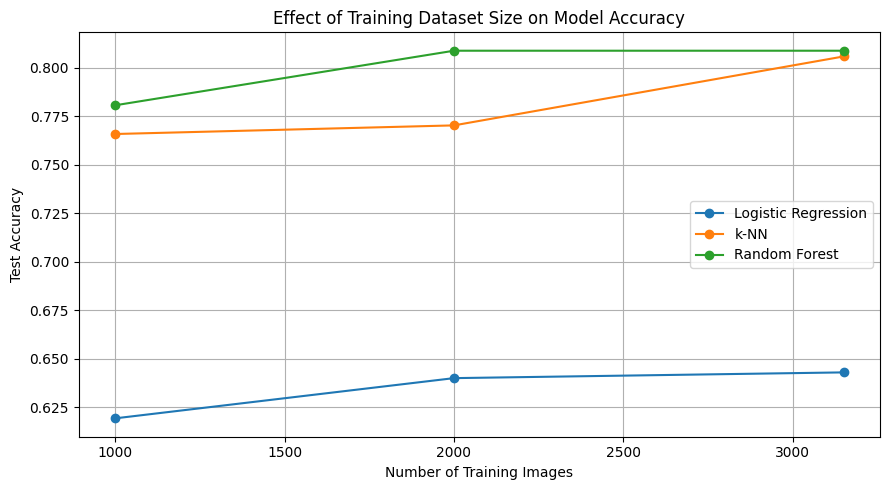

In [ ]:
plt.figure(figsize=(9, 5))

for model_name in models9:
    subset = results9_df[results9_df["Model"] == model_name]

    plt.plot(
        subset["Training images"],
        subset["Accuracy"],
        marker="o",
        label=model_name
    )

plt.xlabel("Number of Training Images")
plt.ylabel("Test Accuracy")
plt.title("Effect of Training Dataset Size on Model Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("task9_accuracy_vs_size.png", dpi=300)
plt.show()

Best model by macro F1: k-NN
Test accuracy: 0.8059
Macro F1: 0.7925


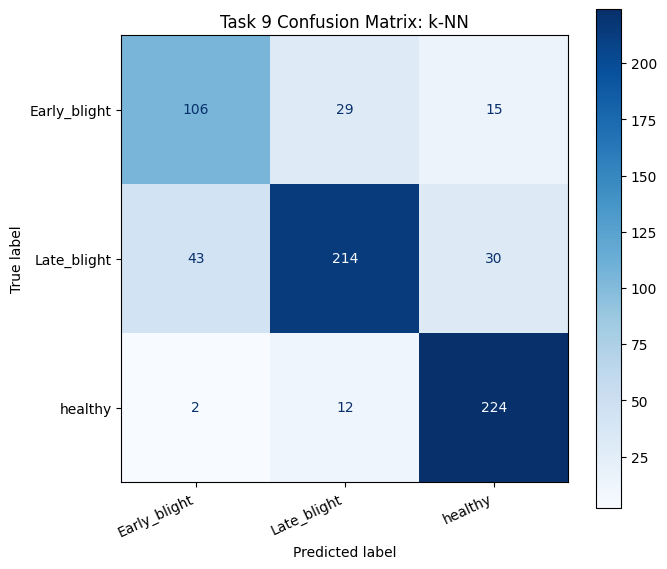

In [ ]:
full_size = len(X9_train)

full_results = results9_df[
    results9_df["Training images"] == full_size
]

best_name = full_results.sort_values(
    "Macro F1", ascending=False
).iloc[0]["Model"]

best_model = saved_models9[(full_size, best_name)]
best_predictions = best_model.predict(X9_test)

print("Best model by macro F1:", best_name)
print("Test accuracy:", round(
    accuracy_score(y_test, best_predictions), 4
))
print("Macro F1:", round(
    f1_score(y_test, best_predictions, average="macro"), 4
))

cm = confusion_matrix(
    y_test, best_predictions,
    labels=best_model.classes_
)

display_labels = [
    label.replace("Tomato___", "")
    for label in best_model.classes_
]

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels
)

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title(f"Task 9 Confusion Matrix: {best_name}")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig("task9_confusion_matrix.png", dpi=300)
plt.show()

TASK 10

In [ ]:
import pandas as pd

print("TASK 10: EXPERIMENTAL EVIDENCE SUMMARY")

# PCA results from Task 2
print("\n1. PCA")
print("Variance explained by 50 components: 78.20%")
print("Variance explained by 100 components: 84.34%")
print("Reconstruction MSE at 50 components: approximately 0.0065")
print("Reconstruction MSE at 100 components: approximately 0.0049")

# Model results from Task 5
print("\n2. Raw vs PCA model accuracy")
display(
    results_df[
        ["Features", "Model", "Accuracy", "Macro F1"]
    ].round(4)
)

# Capacity results from Task 6
print("\n3. Capacity and generalization")
display(results6_df.round(4))

# Bias-variance results from Task 7
print("\n4. Bootstrap bias-variance")
print(f"Squared-bias proxy: {bias_squared:.6f}")
print(f"Prediction variance: {variance:.6f}")

# Optimisation results from Task 8
print("\n5. Best softmax configurations")
display(pd.DataFrame(summary8).head(5).round(4))

# Task 9 results
print("\n6. Performance across training-set sizes")
display(results9_df.round(4))

TASK 10: EXPERIMENTAL EVIDENCE SUMMARY

1. PCA
Variance explained by 50 components: 78.20%
Variance explained by 100 components: 84.34%
Reconstruction MSE at 50 components: approximately 0.0065
Reconstruction MSE at 100 components: approximately 0.0049

2. Raw vs PCA model accuracy


,Features,Model,Accuracy,Macro F1
0,Raw 4096 features,Logistic Regression,0.5733,0.5670
1,Raw 4096 features,k-NN,0.6033,0.6056
2,Raw 4096 features,Random Forest,0.8133,0.7902
3,PCA 50 components,Logistic Regression,0.6233,0.6250
4,PCA 50 components,k-NN,0.7633,0.7481
5,PCA 50 components,Random Forest,0.7967,0.7726



3. Capacity and generalization


,Maximum depth,Training accuracy,Validation accuracy,Training error,Validation error,Generalization gap
0,1,0.4842,0.466,0.5158,0.534,0.0182
1,2,0.5592,0.502,0.4408,0.498,0.0572
2,3,0.6717,0.548,0.3283,0.452,0.1237
3,5,0.7842,0.594,0.2158,0.406,0.1902
4,10,0.9867,0.664,0.0133,0.336,0.3227
5,20,1.0000,0.646,0.0000,0.354,0.3540
6,None,1.0000,0.646,0.0000,0.354,0.3540



4. Bootstrap bias-variance
Squared-bias proxy: 0.146204
Prediction variance: 0.158340

5. Best softmax configurations


,Method,Learning rate,Final validation loss,Validation accuracy,Training time (s)
0,SGD,0.001,0.8247,0.6267,4.6799
1,Mini-batch SGD,0.100,0.8267,0.6167,0.1526
2,SGD,0.010,0.8794,0.5933,3.3665
3,Mini-batch SGD,0.010,0.8799,0.6200,0.1383
4,Batch GD,0.100,0.9314,0.6267,0.0415



6. Performance across training-set sizes


,Training images,Model,Accuracy,Macro precision,Macro recall,Macro F1,Training time (s),Inference time (s)
0,1000,Logistic Regression,0.6193,0.6213,0.6160,0.6182,0.2539,0.0031
1,1000,k-NN,0.7659,0.7527,0.7626,0.7519,0.0043,0.0616
2,1000,Random Forest,0.7807,0.7724,0.7443,0.7531,1.0712,0.0572
3,2000,Logistic Regression,0.6400,0.6390,0.6352,0.6370,0.1218,0.0026
4,2000,k-NN,0.7704,0.7549,0.7591,0.7536,0.0048,0.0413
5,2000,Random Forest,0.8089,0.7942,0.7805,0.7859,1.7090,0.0435
6,3150,Logistic Regression,0.6430,0.6424,0.6372,0.6396,0.1869,0.0007
7,3150,k-NN,0.8059,0.7913,0.7978,0.7925,0.0037,0.0488
8,3150,Random Forest,0.8089,0.7942,0.7795,0.7852,2.7488,0.0633


TASK 11

In [ ]:
import time
import joblib
import os
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Train the raw-pixel Random Forest baseline
rf11 = RandomForestClassifier(
    n_estimators=80,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

start = time.perf_counter()
rf11.fit(Xtr, ytr)
training_time = time.perf_counter() - start

# Measure prediction time over the test batch
start = time.perf_counter()
predictions11 = rf11.predict(Xte)
batch_time = time.perf_counter() - start

per_image_ms = (batch_time / len(Xte)) * 1000

# Measure serialized model size
joblib.dump(rf11, "task11_random_forest.joblib")
model_size_mb = os.path.getsize("task11_random_forest.joblib") / (1024 ** 2)

print("Random Forest deployment diagnostics")
print(f"Test accuracy: {accuracy_score(yte, predictions11):.4f}")
print(f"Training time: {training_time:.4f} seconds")
print(f"Batch prediction time: {batch_time:.4f} seconds")
print(f"Average time per image in this batch: {per_image_ms:.4f} ms")
print(f"Serialized model size: {model_size_mb:.3f} MB")

Random Forest deployment diagnostics
Test accuracy: 0.8133
Training time: 9.6688 seconds
Batch prediction time: 0.0531 seconds
Average time per image in this batch: 0.1768 ms
Serialized model size: 2.041 MB
